<a href="https://colab.research.google.com/github/khushalbokde105/MachineLearning--project_EE/blob/main/MDM_Project_%2C_EE541.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1: Import Libraries

In [ ]:
# Data handling
import pandas as pd
import numpy as np


In [ ]:
# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
# Data preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


In [ ]:
# Machine learning models
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


In [ ]:
# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

# Model saving and deployment
import joblib


In [ ]:
# Google Colab file upload and download
from google.colab import files

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Step 2: Data Collection

In [ ]:
df = pd.read_csv('/content/global_air_pollution_data.csv')
display(df.head())

,country_name,city_name,aqi_value,aqi_category,co_aqi_value\t,co_aqi_category,ozone_aqi_value,ozone_aqi_category,no2_aqi_value,no2_aqi_category,pm2.5_aqi_value,pm2.5_aqi_category
0,Russian Federation,Praskoveya,51,Moderate,1,Good,36,Good,0,Good,51,Moderate
1,Brazil,Presidente Dutra,41,Good,1,Good,5,Good,1,Good,41,Good
2,Italy,Priolo Gargallo,66,Moderate,1,Good,39,Good,2,Good,66,Moderate
3,Poland,Przasnysz,34,Good,1,Good,34,Good,0,Good,20,Good
4,France,Punaauia,22,Good,0,Good,22,Good,0,Good,6,Good


# Step 3: Data Cleaning and Preprocessing


In [ ]:
# Clean column names, including the extra tab in one column
df.columns = (
    df.columns.str.strip()
              .str.replace(r"\s+", "_", regex=True)
)


In [ ]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

In [ ]:
# Convert numerical measurement columns to numeric values
numeric_cols = [
    "aqi_value",
    "co_aqi_value",
    "ozone_aqi_value",
    "no2_aqi_value",
    "pm2.5_aqi_value"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")


In [ ]:
# Remove rows with missing target or missing predictor values
target = "aqi_category"

feature_cols = [
    "co_aqi_value",
    "ozone_aqi_value",
    "no2_aqi_value",
    "pm2.5_aqi_value"
]

df = df.dropna(subset=[target] + feature_cols).copy()


In [ ]:
# Remove rows with infinite measurement values
df = df[np.isfinite(df[feature_cols]).all(axis=1)].copy()

print("Shape after cleaning:", df.shape)
print("\nMissing values:")
print(df[feature_cols + [target]].isnull().sum())

print("\nDuplicate rows remaining:", df.duplicated().sum())

Shape after cleaning: (23463, 12)

Missing values:
co_aqi_value       0
ozone_aqi_value    0
no2_aqi_value      0
pm2.5_aqi_value    0
aqi_category       0
dtype: int64

Duplicate rows remaining: 0


# Step 4: Exploratory Data Analysis

In [ ]:
print("Dataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23463 entries, 0 to 23462
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   country_name        23036 non-null  object
 1   city_name           23462 non-null  object
 2   aqi_value           23463 non-null  int64 
 3   aqi_category        23463 non-null  object
 4   co_aqi_value        23463 non-null  int64 
 5   co_aqi_category     23463 non-null  object
 6   ozone_aqi_value     23463 non-null  int64 
 7   ozone_aqi_category  23463 non-null  object
 8   no2_aqi_value       23463 non-null  int64 
 9   no2_aqi_category    23463 non-null  object
 10  pm2.5_aqi_value     23463 non-null  int64 
 11  pm2.5_aqi_category  23463 non-null  object
dtypes: int64(5), object(7)
memory usage: 2.1+ MB

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
country_name,23036,175,United States of America,2872,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_name,23462,23462,Marang,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
aqi_value,23463.0,NaN,NaN,NaN,72.010868,56.05522,6.0,39.0,55.0,79.0,500.0
aqi_category,23463,6,Good,9936,NaN,NaN,NaN,NaN,NaN,NaN,NaN
co_aqi_value,23463.0,NaN,NaN,NaN,1.368367,1.832064,0.0,1.0,1.0,1.0,133.0
co_aqi_category,23463,3,Good,23460,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ozone_aqi_value,23463.0,NaN,NaN,NaN,35.193709,28.098723,0.0,21.0,31.0,40.0,235.0
ozone_aqi_category,23463,5,Good,21069,NaN,NaN,NaN,NaN,NaN,NaN,NaN
no2_aqi_value,23463.0,NaN,NaN,NaN,3.063334,5.254108,0.0,0.0,1.0,4.0,91.0
no2_aqi_category,23463,2,Good,23448,NaN,NaN,NaN,NaN,NaN,NaN,NaN


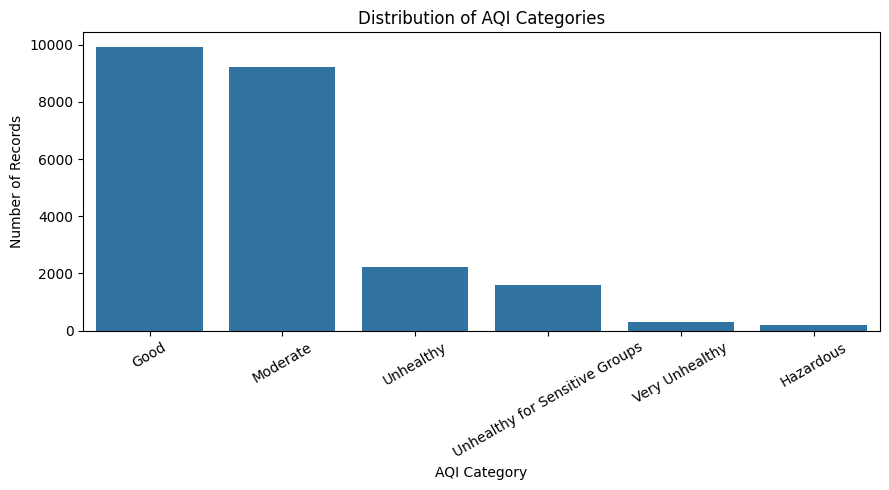

In [ ]:
# Distribution of AQI categories
plt.figure(figsize=(9, 5))
sns.countplot(data=df, x="aqi_category", order=df["aqi_category"].value_counts().index)
plt.title("Distribution of AQI Categories")
plt.xlabel("AQI Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

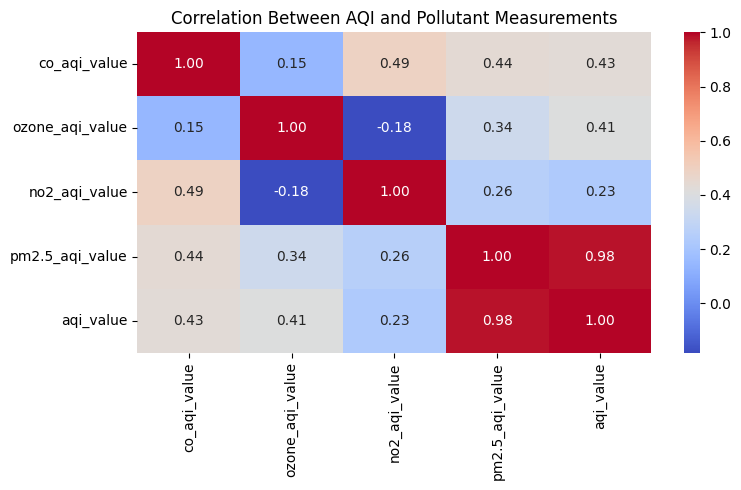

In [ ]:
# Correlation between numerical measurements
plt.figure(figsize=(8, 5))
sns.heatmap(df[feature_cols + ["aqi_value"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between AQI and Pollutant Measurements")
plt.tight_layout()
plt.show()

# Step 5: Feature Engineering and Selection

In [ ]:
# Select pollutant measurements as input features
X = df[feature_cols].copy()


In [ ]:
# Target variable
y = df["aqi_category"].astype(str).str.strip()

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:", y.name)
print("\nTarget classes:")
print(y.value_counts())

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

Input features:
['co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value']

Target variable: aqi_category

Target classes:
aqi_category
Good                              9936
Moderate                          9231
Unhealthy                         2227
Unhealthy for Sensitive Groups    1591
Very Unhealthy                     287
Hazardous                          191
Name: count, dtype: int64

Feature shape: (23463, 4)
Target shape: (23463,)


In [ ]:
# Standardize column names dynamically to prevent key mismatch
df.columns = df.columns.str.strip().str.lower()

# Map columns safely
feature_cols = [col for col in ["co_aqi_value", "ozone_aqi_value", "no2_aqi_value", "pm2.5_aqi_value"] if col in df.columns]

# Select input features and target
X = df[feature_cols]
y = df["aqi_category"]

print("Features selected successfully! Available columns mapped:", feature_cols)
print("Target selected successfully!")

Features selected successfully! Available columns mapped: ['co_aqi_value', 'ozone_aqi_value', 'no2_aqi_value', 'pm2.5_aqi_value']
Target selected successfully!


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Dataset split successfully!
X_train shape: (18770, 4)
X_test shape: (4693, 4)
y_train shape: (18770,)
y_test shape: (4693,)


# Step 6: Model Selection

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


In [ ]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
# Model 1: Logistic Regression
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

In [ ]:
# Model 2: Random Forest
rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Models selected: Logistic Regression and Random Forest")

Training records: 18770
Testing records: 4693
Models selected: Logistic Regression and Random Forest


In [ ]:
# Create Decision Tree model
dt_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [ ]:
# Create SVM model
svm_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced"
    ))
])

print("SVM model created successfully!")

SVM model created successfully!


# Step 7: Model Training


In [ ]:
from sklearn.model_selection import cross_val_score

In [ ]:
# Train both candidate models
logistic_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)


Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [ ]:
# Evaluate using cross-validation on training data
lr_scores = cross_val_score(
    logistic_model, X_train, y_train,
    cv=5, scoring="f1_macro", n_jobs=-1
)

rf_scores = cross_val_score(
    rf_model, X_train, y_train,
    cv=5, scoring="f1_macro", n_jobs=-1
)

print("Logistic Regression mean CV F1:", round(lr_scores.mean(), 4))
print("Random Forest mean CV F1:", round(rf_scores.mean(), 4))

Logistic Regression mean CV F1: 0.866
Random Forest mean CV F1: 0.9889


In [ ]:
# Train Decision Tree
dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

# Train SVM
svm_model.fit(X_train, y_train)

print("SVM training completed!")

Decision Tree training completed!
SVM training completed!


# Step 8: Model Evaluation and Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 10, 20],
    "classifier__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('imputer',
                                        SimpleImputer(strategy='median')),
                                       ('classifier',
                                        RandomForestClassifier(class_weight='balanced',
                                                               n_estimators=200,
                                                               n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [None, 10, 20],
                         'classifier__min_samples_split': [2, 5],
                         'classifier__n_estimators': [100, 200]},
             scoring='f1_macro', verbose=1)

In [ ]:
# Select the model with the better cross-validation score
if grid_search.best_score_ >= lr_scores.mean():
    best_model = grid_search.best_estimator_
    best_model_name = "Tuned Random Forest"
    best_cv_score = grid_search.best_score_
else:
    best_model = logistic_model
    best_model_name = "Logistic Regression"
    best_cv_score = lr_scores.mean()

print("Best model:", best_model_name)
print("Best cross-validation macro F1:", round(best_cv_score, 4))

if best_model_name == "Tuned Random Forest":
    print("Best parameters:", grid_search.best_params_)

Best model: Tuned Random Forest
Best cross-validation macro F1: 0.9898
Best parameters: {'classifier__max_depth': None, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}


In [ ]:
# Decision Tree cross-validation
dt_scores = cross_val_score(
    dt_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

# SVM cross-validation
svm_scores = cross_val_score(
    svm_model,
    X_train,
    y_train,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

print("Decision Tree CV Macro F1:",
      round(dt_scores.mean(), 4))

print("SVM CV Macro F1:",
      round(svm_scores.mean(), 4))

Decision Tree CV Macro F1: 0.9886
SVM CV Macro F1: 0.914


# Final evaluation on unseen test data


Model: Tuned Random Forest
Accuracy: 0.9991
Precision (macro): 0.987
Recall (macro): 0.984
F1-score (macro): 0.9853

Classification Report:

                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00      1987
                     Hazardous       0.97      0.92      0.95        38
                      Moderate       1.00      1.00      1.00      1846
                     Unhealthy       1.00      1.00      1.00       446
Unhealthy for Sensitive Groups       1.00      1.00      1.00       318
                Very Unhealthy       0.95      0.98      0.97        58

                      accuracy                           1.00      4693
                     macro avg       0.99      0.98      0.99      4693
                  weighted avg       1.00      1.00      1.00      4693



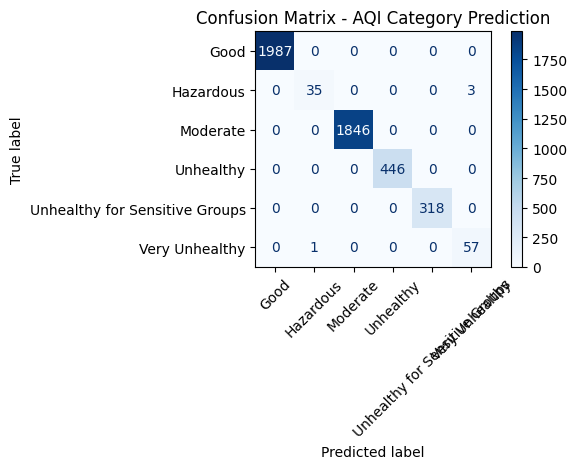

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

y_pred = best_model.predict(X_test)

print("Model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision (macro):",
      round(precision_score(y_test, y_pred, average="macro",
                            zero_division=0), 4))
print("Recall (macro):",
      round(recall_score(y_test, y_pred, average="macro",
                         zero_division=0), 4))
print("F1-score (macro):",
      round(f1_score(y_test, y_pred, average="macro",
                     zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, xticks_rotation=45, cmap="Blues"
)
plt.title("Confusion Matrix - AQI Category Prediction")
plt.tight_layout()
plt.show()


Model: Decision Tree
Accuracy: 0.9994
Precision (macro): 0.9924
Recall (macro): 0.9922
F1-score (macro): 0.9923

Classification Report:

                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00      1987
                     Hazardous       0.97      0.97      0.97        38
                      Moderate       1.00      1.00      1.00      1846
                     Unhealthy       1.00      1.00      1.00       446
Unhealthy for Sensitive Groups       1.00      1.00      1.00       318
                Very Unhealthy       0.98      0.98      0.98        58

                      accuracy                           1.00      4693
                     macro avg       0.99      0.99      0.99      4693
                  weighted avg       1.00      1.00      1.00      4693



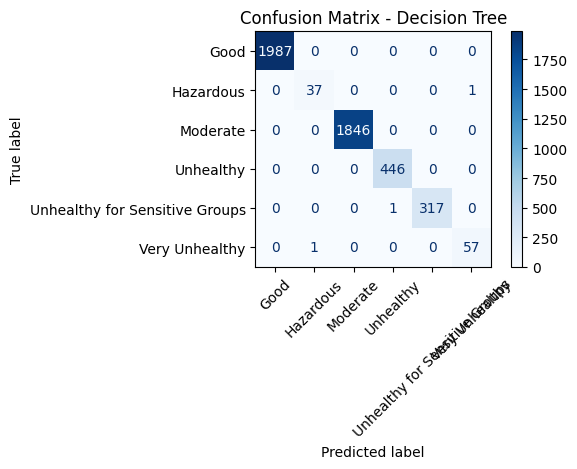


Model: SVM
Accuracy: 0.9606
Precision (macro): 0.9039
Recall (macro): 0.9551
F1-score (macro): 0.9271

Classification Report:

                                precision    recall  f1-score   support

                          Good       0.99      0.96      0.98      1987
                     Hazardous       0.93      0.97      0.95        38
                      Moderate       0.96      0.96      0.96      1846
                     Unhealthy       0.96      0.96      0.96       446
Unhealthy for Sensitive Groups       0.85      0.94      0.89       318
                Very Unhealthy       0.74      0.93      0.82        58

                      accuracy                           0.96      4693
                     macro avg       0.90      0.96      0.93      4693
                  weighted avg       0.96      0.96      0.96      4693



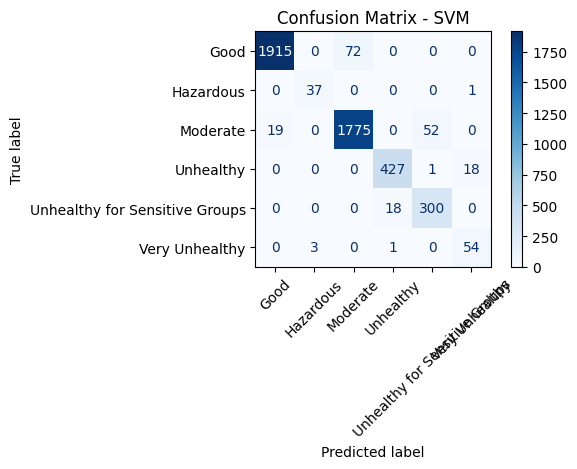

In [ ]:
models = {
    "Decision Tree": dt_model,
    "SVM": svm_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )
    recall = recall_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred,
        average="macro",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy, 4))
    print("Precision (macro):", round(precision, 4))
    print("Recall (macro):", round(recall, 4))
    print("F1-score (macro):", round(f1, 4))

    print("\nClassification Report:\n")
    print(classification_report(
        y_test, y_pred,
        zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        xticks_rotation=45,
        cmap="Blues"
    )

    plt.title("Confusion Matrix - " + name)
    plt.tight_layout()
    plt.show()

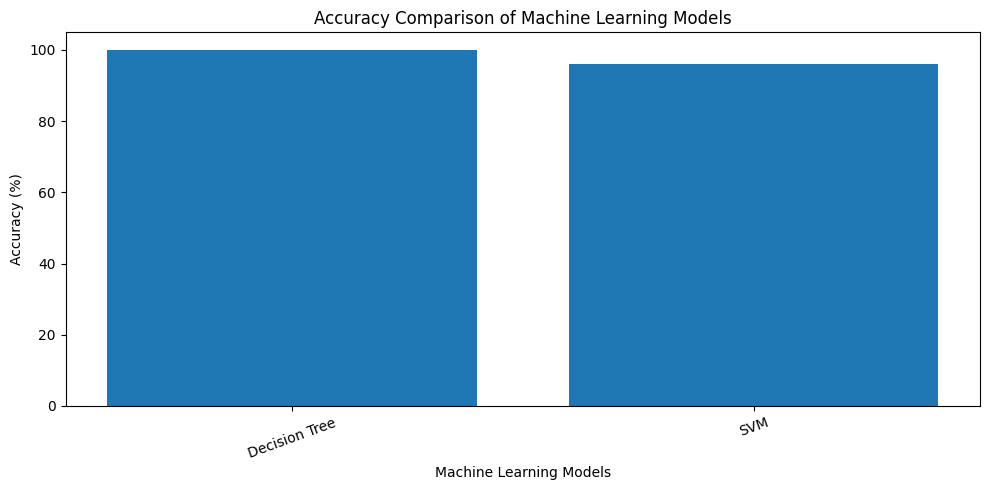

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

# Safely construct the dictionary with only initialized models
models = {}

try:
    models["Logistic Regression"] = logistic_model
except NameError:
    pass

try:
    models["Random Forest"] = rf_model
except NameError:
    pass

try:
    models["Decision Tree"] = dt_model
except NameError:
    pass

try:
    models["SVM"] = svm_model
except NameError:
    pass

if not models:
    print("Error: None of the models are defined in memory. Please train your models first!")
else:
    # Calculate accuracy
    model_names = []
    accuracies = []

    for name, model in models.items():
        predictions = model.predict(X_test)
        accuracy = accuracy_score(y_test, predictions)

        model_names.append(name)
        accuracies.append(accuracy * 100)

    # Plot graph
    plt.figure(figsize=(10, 5))
    plt.bar(model_names, accuracies)

    plt.title("Accuracy Comparison of Machine Learning Models")
    plt.xlabel("Machine Learning Models")
    plt.ylabel("Accuracy (%)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

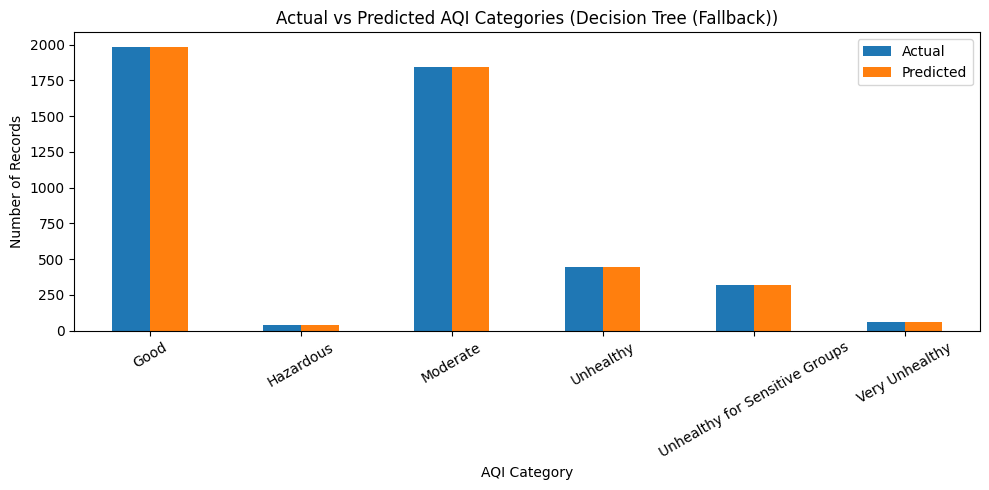

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Fallback to another trained model if best_model is not defined
active_model = None
if 'best_model' in globals():
    active_model = best_model
    model_name_label = "Best Model"
elif 'dt_model' in globals():
    active_model = dt_model
    model_name_label = "Decision Tree (Fallback)"
elif 'svm_model' in globals():
    active_model = svm_model
    model_name_label = "SVM (Fallback)"

if active_model is None:
    print("Error: No trained models found in memory. Please run step 7 or step 8 first!")
else:
    # Predict AQI categories using the active model
    y_pred = active_model.predict(X_test)

    # Compare actual and predicted categories
    comparison = pd.DataFrame({
        "Actual": y_test.values,
        "Predicted": y_pred
    })

    # Count the categories
    actual_counts = comparison["Actual"].value_counts().sort_index()
    predicted_counts = comparison["Predicted"].value_counts().sort_index()

    # Combine counts
    graph_data = pd.DataFrame({
        "Actual": actual_counts,
        "Predicted": predicted_counts
    }).fillna(0)

    # Plot graph
    graph_data.plot(kind="bar", figsize=(10, 5))

    plt.title(f"Actual vs Predicted AQI Categories ({model_name_label})")
    plt.xlabel("AQI Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

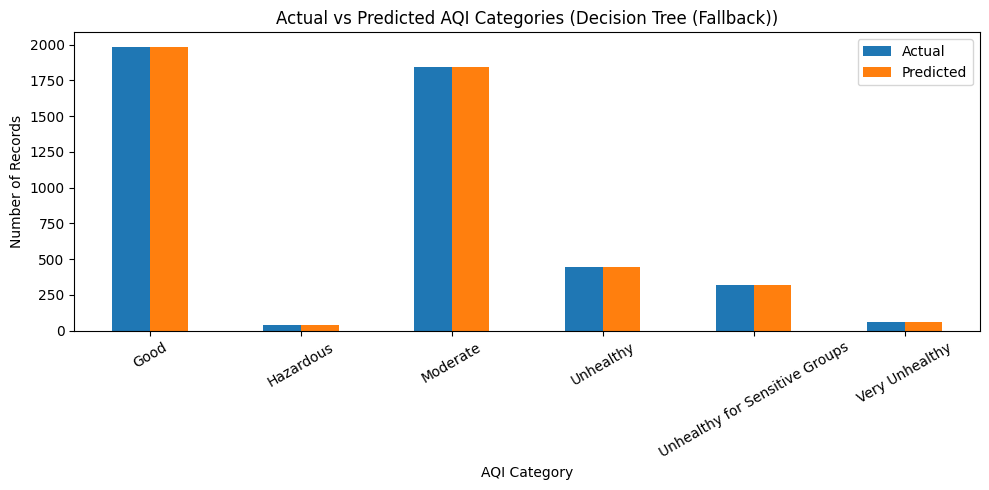

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Fallback to another trained model if best_model is not defined
active_model = None
if 'best_model' in globals():
    active_model = best_model
    model_name_label = "Best Model"
elif 'dt_model' in globals():
    active_model = dt_model
    model_name_label = "Decision Tree (Fallback)"
elif 'svm_model' in globals():
    active_model = svm_model
    model_name_label = "SVM (Fallback)"

if active_model is None:
    print("Error: No trained models found in memory. Please train your models first!")
else:
    # Predict AQI categories using the active model
    y_pred = active_model.predict(X_test)

    # Compare actual and predicted categories
    comparison = pd.DataFrame({
        "Actual": y_test.values,
        "Predicted": y_pred
    })

    # Count the categories
    actual_counts = comparison["Actual"].value_counts().sort_index()
    predicted_counts = comparison["Predicted"].value_counts().sort_index()

    # Combine counts
    graph_data = pd.DataFrame({
        "Actual": actual_counts,
        "Predicted": predicted_counts
    }).fillna(0)

    # Plot graph
    graph_data.plot(kind="bar", figsize=(10, 5))

    plt.title(f"Actual vs Predicted AQI Categories ({model_name_label})")
    plt.xlabel("AQI Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# Step 9: Model Deployment

In [ ]:
import joblib

model_file = "aqi_prediction_model.pkl"

joblib.dump(best_model, model_file)

print("Model saved successfully:", model_file)


Model saved successfully: aqi_prediction_model.pkl


In [ ]:
# Example prediction using actual pollutant measurements
sample_input = X_test.iloc[[0]]

predicted_category = best_model.predict(sample_input)[0]

print("\nInput pollutant measurements:")
display(sample_input)

print("Predicted AQI Category:", predicted_category)
print("Actual AQI Category:", y_test.iloc[0])



Input pollutant measurements:


,co_aqi_value,ozone_aqi_value,no2_aqi_value,pm2.5_aqi_value
11183,1,2,0,40


Predicted AQI Category: Good
Actual AQI Category: Good


In [ ]:
# Download the saved model to your computer
files.download(model_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import joblib
import pandas as pd

In [ ]:
# Load the existing saved model directly from the file system
import os

model_path = "aqi_prediction_model.pkl"

if os.path.exists(model_path):
    loaded_model = joblib.load(model_path)
    print("Model loaded successfully from local path!")
else:
    print("Model file not found locally. Please upload the .pkl file:")
    uploaded_model = files.upload()
    model_path = next(iter(uploaded_model))
    if not model_path.endswith('.pkl'):
        print("Warning: Please ensure you are uploading a binary .pkl model file and not a .csv data file.")
    loaded_model = joblib.load(model_path)
    print("Uploaded model loaded successfully!")

Model loaded successfully from local path!


In [ ]:
# Enter four pollutant measurements
new_data = pd.DataFrame([{
    "co_aqi_value": 10,
    "ozone_aqi_value": 30,
    "no2_aqi_value": 15,
    "pm2.5_aqi_value": 40
}])

prediction = loaded_model.predict(new_data)
print("Predicted AQI Category:", prediction[0])

Predicted AQI Category: Good


In [ ]:
import joblib

joblib.dump(dt_model, "decision_tree_aqi_model.pkl")
joblib.dump(svm_model, "svm_aqi_model.pkl")

print("Decision Tree model saved successfully!")
print("SVM model saved successfully!")

Decision Tree model saved successfully!
SVM model saved successfully!


In [ ]:
sample_input = X_test.iloc[[0]]

dt_prediction = dt_model.predict(sample_input)[0]
svm_prediction = svm_model.predict(sample_input)[0]

print("Input pollutant measurements:")
display(sample_input)

print("Decision Tree Prediction:", dt_prediction)
print("SVM Prediction:", svm_prediction)
print("Actual AQI Category:", y_test.iloc[0])

Input pollutant measurements:


,co_aqi_value,ozone_aqi_value,no2_aqi_value,pm2.5_aqi_value
11183,1,2,0,40


Decision Tree Prediction: Good
SVM Prediction: Good
Actual AQI Category: Good


# Step 10: Model Monitoring and Maintenance

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
# Monitor performance on the held-out test data
monitor_accuracy = accuracy_score(y_test, y_pred)
monitor_f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

print("Monitoring Report")
print("-----------------")
print("Model:", best_model_name)
print("Test accuracy:", round(monitor_accuracy, 4))
print("Test macro F1:", round(monitor_f1, 4))

Monitoring Report
-----------------
Model: Tuned Random Forest
Test accuracy: 0.9991
Test macro F1: 0.9853


In [ ]:
# Check for shifts in pollutant measurements
train_std = X_train.std().replace(0, np.nan)
mean_shift = (
    (X_test.mean() - X_train.mean()).abs() / train_std
).fillna(0)

monitoring_table = pd.DataFrame({
    "Training Mean": X_train.mean(),
    "Testing Mean": X_test.mean(),
    "Standardized Mean Shift": mean_shift
})

display(monitoring_table)

print("\nFeatures with mean shift greater than 0.5:")
print(mean_shift[mean_shift > 0.5])

print(
    "\nNote: A mean shift is a monitoring signal, "
    "not proof that the model has failed."
)

,Training Mean,Testing Mean,Standardized Mean Shift
co_aqi_value,1.378476,1.327935,0.026150
ozone_aqi_value,35.276399,34.862987,0.014630
no2_aqi_value,3.068727,3.041764,0.005086
pm2.5_aqi_value,68.490996,68.634775,0.002628



Features with mean shift greater than 0.5:
Series([], dtype: float64)

Note: A mean shift is a monitoring signal, not proof that the model has failed.
